In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

In [3]:
df = pd.read_csv("../data/raw/student-por.csv", sep=";")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (649, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [4]:
ml_data = df.copy()

# Remove G1 and G2 to predict performance without previous grades
ml_data = ml_data.drop(columns=["G1", "G2"])

# Input features
X = ml_data.drop(columns=["G3"])

# Target variable
y = ml_data["G3"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (649, 30)
Target shape: (649,)


In [5]:
X = pd.get_dummies(X, drop_first=True, dtype=int)

print("After encoding:", X.shape)

X.head()

After encoding: (649, 39)


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,...,guardian_mother,guardian_other,schoolsup_yes,famsup_yes,paid_yes,activities_yes,nursery_yes,higher_yes,internet_yes,romantic_yes
0,18,4,4,2,2,0,4,3,4,1,...,1,0,1,0,0,0,1,1,0,0
1,17,1,1,1,2,0,5,3,3,1,...,0,0,0,1,0,0,0,1,1,0
2,15,1,1,1,2,0,4,3,2,2,...,1,0,1,0,0,0,1,1,1,0
3,15,4,2,1,3,0,3,2,2,1,...,1,0,0,1,0,1,1,1,1,1
4,16,3,3,1,2,0,4,3,2,1,...,0,0,0,1,0,0,1,1,0,0


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (519, 39)
Testing data: (130, 39)


In [7]:
baseline_model = DummyRegressor(strategy="mean")

baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)

print("Baseline model trained!")

Baseline model trained!


In [8]:
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

print("Linear Regression model trained!")

Linear Regression model trained!


In [9]:
tree_model = DecisionTreeRegressor(
    max_depth=5,
    random_state=42
)

tree_model.fit(X_train, y_train)

tree_predictions = tree_model.predict(X_test)

print("Decision Tree model trained!")

Decision Tree model trained!


In [10]:
random_forest_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=10,
    random_state=42
)

random_forest_model.fit(X_train, y_train)

forest_predictions = random_forest_model.predict(X_test)

print("Random Forest model trained!")

Random Forest model trained!


In [11]:
def evaluate_model(name, actual, predicted):

    mae = mean_absolute_error(actual, predicted)
    mse = mean_squared_error(actual, predicted)
    rmse = np.sqrt(mse)
    r2 = r2_score(actual, predicted)

    return {
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    }


results = []

results.append(evaluate_model("Baseline", y_test, baseline_predictions))
results.append(evaluate_model("Linear Regression", y_test, linear_predictions))
results.append(evaluate_model("Decision Tree", y_test, tree_predictions))
results.append(evaluate_model("Random Forest", y_test, forest_predictions))

results_df = pd.DataFrame(results)

results_df

,Model,MAE,MSE,RMSE,R2 Score
0,Baseline,2.394605,10.065329,3.172590,-0.032160
1,Linear Regression,2.156382,8.189784,2.861780,0.160170
2,Decision Tree,2.475242,11.147018,3.338715,-0.143083
3,Random Forest,2.051440,7.961819,2.821670,0.183547


In [12]:
results_df = results_df.sort_values(by="RMSE")

results_df

,Model,MAE,MSE,RMSE,R2 Score
3,Random Forest,2.051440,7.961819,2.821670,0.183547
1,Linear Regression,2.156382,8.189784,2.861780,0.160170
0,Baseline,2.394605,10.065329,3.172590,-0.032160
2,Decision Tree,2.475242,11.147018,3.338715,-0.143083


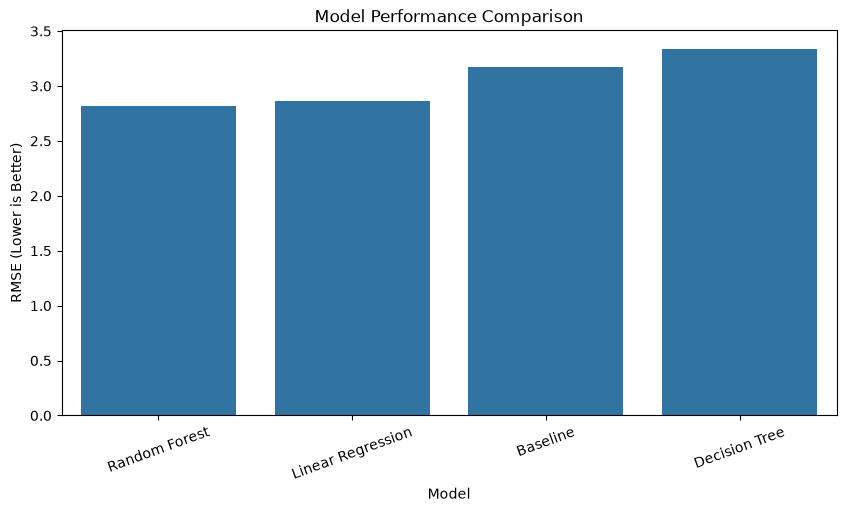

In [13]:
plt.figure(figsize=(10, 5))

sns.barplot(data=results_df, x="Model", y="RMSE")

plt.title("Model Performance Comparison")
plt.ylabel("RMSE (Lower is Better)")
plt.xticks(rotation=20)

plt.show()

In [14]:
best_model_name = results_df.iloc[0]["Model"]

models = {
    "Baseline": baseline_model,
    "Linear Regression": linear_model,
    "Decision Tree": tree_model,
    "Random Forest": random_forest_model
}

best_model = models[best_model_name]

best_predictions = best_model.predict(X_test)

comparison = pd.DataFrame({
    "Actual Grade": y_test.values,
    "Predicted Grade": best_predictions
})

comparison.head(15)

,Actual Grade,Predicted Grade
0,19,11.504603
1,12,12.430117
2,18,13.012282
3,11,12.095159
4,11,11.958021
5,17,12.398908
6,18,14.379375
7,8,8.963141
8,10,12.087282
9,11,12.310494


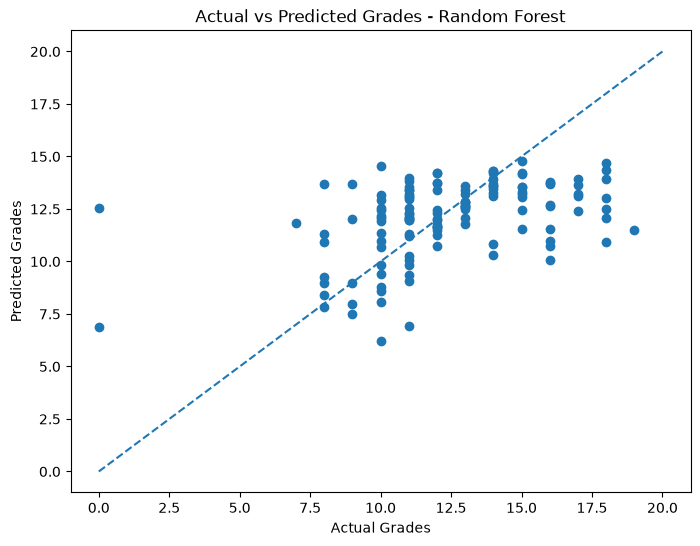

In [15]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, best_predictions)

plt.xlabel("Actual Grades")
plt.ylabel("Predicted Grades")
plt.title(f"Actual vs Predicted Grades - {best_model_name}")

plt.plot([0, 20], [0, 20], linestyle="--")

plt.show()

,Feature,Importance
5,failures,0.226908
12,absences,0.071737
13,school_MS,0.052599
2,Fedu,0.047615
9,Dalc,0.044612
10,Walc,0.039389
7,freetime,0.036211
0,age,0.033517
36,higher_yes,0.033368
11,health,0.033242


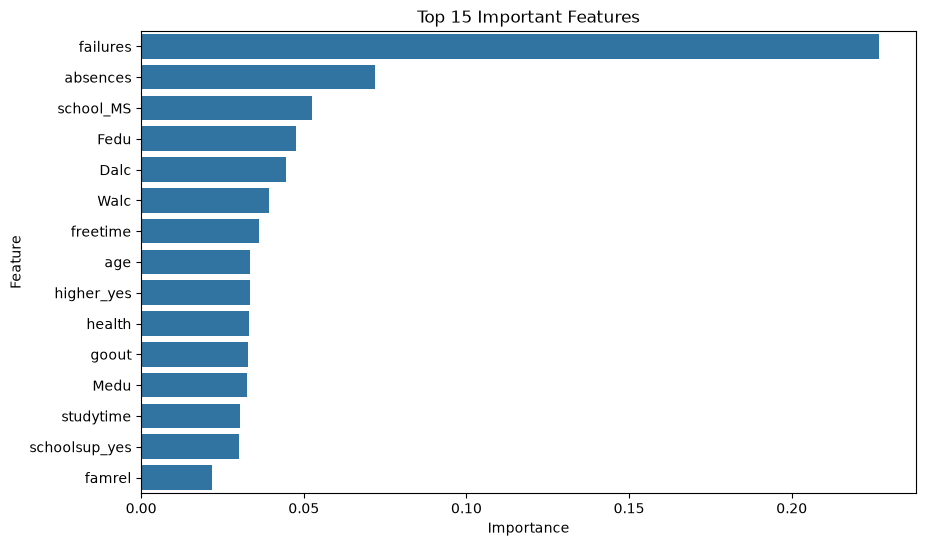

In [16]:
if hasattr(best_model, "feature_importances_"):

    importance = pd.DataFrame({
        "Feature": X.columns,
        "Importance": best_model.feature_importances_
    })

    importance = importance.sort_values(
        by="Importance",
        ascending=False
    )

    display(importance.head(15))

    plt.figure(figsize=(10, 6))

    sns.barplot(
        data=importance.head(15),
        x="Importance",
        y="Feature"
    )

    plt.title("Top 15 Important Features")

    plt.show()

else:
    print("Feature importance is not directly available for this model.")

In [17]:
student = X_test.iloc[[0]]

predicted_grade = best_model.predict(student)

print("Predicted final grade:", round(predicted_grade[0], 2))
print("Actual final grade:", y_test.iloc[0])

Predicted final grade: 11.5
Actual final grade: 19


In [18]:
import os
import joblib

os.makedirs("../models", exist_ok=True)

joblib.dump(best_model, "../models/best_student_model.pkl")

joblib.dump(X.columns.tolist(), "../models/model_columns.pkl")

print("Model saved successfully!")

Model saved successfully!
